# Ingatlanár-becslés — modellezés és kiértékelés

Ez a notebook a `01_eda_and_preprocessing.ipynb` kimenetére
(`data/properties_preprocessed.csv`) épül, és a `plan.md`-ben kijelölt
fő irányt viszi végig: **regresszió az ár (pontosabban `log_price`) becslésére**.

Négy, egymásra épülő kísérletet futtatunk:

1. **Teljes adathalmaz** (minden ingatlantípus, az 1-elemű `beruhazas`
   osztály kivételével) — három modell (Lineáris regresszió, Ridge, Random
   Forest) összehasonlítása, fix hiperparaméterekkel.
2. **Szűkített adathalmaz** (csak `ház` és `lakás`) — mivel a `telek` és `nyaralo`
   kategóriák más piaci logikát követnek és a `area_sqm` skálája is eltér
   (egy telek m²-ben sokkal nagyobb, mint egy lakás alapterülete), megnézzük,
   javít-e a homogénebb részhalmazra szűkítés.
3. **Kiugró értékek eltávolítása** a szűkített adathalmazon — az előfeldolgozó
   notebookban már jelölt (1./99. percentilis alapján kiugrónak jelölt) sorok
   kihagyásának hatása.
4. **Hiperparaméter-keresés** `sklearn.model_selection.RandomizedSearchCV`-vel
   a 3. kísérlet adatain (Random Forest + Ridge), hogy a fix beállítások
   helyett a keresztvalidáció alapján optimalizált hiperparaméterekkel is
   lássuk az elérhető eredményt.

Minden kísérletnél 80/20 train/test felosztást és 5-fold keresztvalidációt
használunk a train részen, a végső kiértékelés pedig a (modellillesztésben
sosem látott) teszthalmazon történik.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)
RANDOM_STATE = 42

df = pd.read_csv("../data/properties_preprocessed.csv")
print("Betöltött (előfeldolgozott) sorok, oszlopok:", df.shape)


Betöltött (előfeldolgozott) sorok, oszlopok: (1525, 45)


## 1. Kísérlet — teljes adathalmaz, modellösszehasonlítás

A `beruhazas` típusból csak 1 hirdetés van, ezen semmilyen modell nem tud
általánosítani (sem tanítani, sem érdemben kiértékelni rajta), ezért ezt a
sort kihagyjuk a modellezésből — ez összhangban van az EDA notebook 3.
pontjának következtetésével. A `sorhaz` típust (mára érdemi, nem 1-elemű
mintaszámmal) viszont a teljes adathalmaz-kísérletben megtartjuk.

Jellemzők (feature-ök):

- `log_area_sqm` — log-transzformált alapterület,
- `rooms`, `rooms_missing` — (imputált) szobaszám + hiány-jelző,
- `is_budapest`, `has_coords`, `dist_to_bp_km` — helyszín-jellemzők,
- `type_lakas`, `type_nyaralo`, `type_telek`, `type_sorhaz` — ingatlantípus
  one-hot (a `ház` a referenciakategória, ezért nincs rá külön oszlop).

A `dist_to_bp_km`-nél a koordináta nélküli sorokra a medián távolsággal
pótolunk (ezeket a `has_coords=0` flag jelzi a modell felé).


In [2]:
df_model = df[~df["type_beruhazas"].astype(bool)].copy()
df_model["dist_to_bp_km"] = df_model["dist_to_bp_km"].fillna(df_model["dist_to_bp_km"].median())
print("Modellezésbe bekerülő sorok (beruhazas nélkül):", df_model.shape)

FEATURES_FULL = [
    "log_area_sqm", "rooms", "rooms_missing",
    "is_budapest", "has_coords", "dist_to_bp_km",
    "type_lakas", "type_nyaralo", "type_telek", "type_sorhaz",
]
TARGET = "log_price"


Modellezésbe bekerülő sorok (beruhazas nélkül): (1524, 45)


In [3]:
def evaluate_models(data, features, target=TARGET, label=""):
    """Train/test split + 5-fold CV + teszt-kiértékelés egy adott feature-halmazon.

    Visszaadja a fitted modelleket és egy összehasonlító DataFrame-et, hogy a
    teszthalmazon kapott predikciókat/reziduumokat is tovább lehessen vizsgálni.
    """
    X = data[features]
    y = data[target]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE
    )

    models = {
        "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge (alpha=1.0)": make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=RANDOM_STATE)),
        "RandomForest": RandomForestRegressor(
            n_estimators=300, max_depth=6, random_state=RANDOM_STATE
        ),
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    fitted = {}
    for name, model in models.items():
        cv_mae = -cross_val_score(model, X_train, y_train, cv=kf, scoring="neg_mean_absolute_error")
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        mae_log = mean_absolute_error(y_test, pred)
        rmse_log = mean_squared_error(y_test, pred) ** 0.5
        r2 = r2_score(y_test, pred)

        pred_huf = np.expm1(pred)
        true_huf = np.expm1(y_test)
        mae_huf = mean_absolute_error(true_huf, pred_huf)
        mape = np.mean(np.abs((true_huf - pred_huf) / true_huf)) * 100

        rows.append({
            "modell": name,
            "CV MAE (log, train)": round(cv_mae.mean(), 3),
            "CV MAE std": round(cv_mae.std(), 3),
            "teszt MAE (log)": round(mae_log, 3),
            "teszt RMSE (log)": round(rmse_log, 3),
            "teszt R2": round(r2, 3),
            "teszt MAE (HUF)": round(mae_huf),
            "teszt MAPE (%)": round(mape, 1),
        })
        fitted[name] = model

    result = pd.DataFrame(rows).set_index("modell")
    print(f"=== {label} (n={len(data)}, train={len(X_train)}, test={len(X_test)}) ===")
    print(result)
    return fitted, result, (X_train, X_test, y_train, y_test)


fitted_full, result_full, split_full = evaluate_models(
    df_model, FEATURES_FULL, label="1. kísérlet: teljes adathalmaz"
)


=== 1. kísérlet: teljes adathalmaz (n=1524, train=1219, test=305) ===
                   CV MAE (log, train)  CV MAE std  teszt MAE (log)  \
modell                                                                
LinearRegression                 0.401       0.019            0.375   
Ridge (alpha=1.0)                0.401       0.019            0.375   
RandomForest                     0.284       0.013            0.261   

                   teszt RMSE (log)  teszt R2  teszt MAE (HUF)  teszt MAPE (%)  
modell                                                                          
LinearRegression              0.486     0.591         25006045            43.1  
Ridge (alpha=1.0)             0.486     0.591         25024844            43.1  
RandomForest                  0.390     0.737         18738184            30.3  


### Értelmezés

A három modell közül a **Random Forest** adja a legjobb teszteredményt
(alacsonyabb hiba, magasabb R²), ami arra utal, hogy az ár és a jellemzők
(elsősorban terület és helyszín) kapcsolata **nem tisztán lineáris** —
ezt egy fastruktúra-alapú modell jobban tudja kezelni, mint a lineáris/Ridge
regresszió. A hiba (MAPE ≈ 30%) a nagyobb adatkészleten már ezen a teljes
(minden típust tartalmazó) halmazon is viszonylag alacsony, de a `telek`
(földterület) és a `nyaralo` (üdülő) kategóriák továbbra is más piaci
logikát követnek, és az `area_sqm` jelentése is más (telekméret vs.
lakóterület) — ezt vizsgáljuk meg a 2. kísérletben.


## 2. Kísérlet — szűkített adathalmaz: csak `ház` és `lakás`

Ez a két kategória a legnagyobb mintájú (a teljes adat nagy többsége), és
mindkettőnél a `area_sqm` ugyanazt jelenti (lakóterület), így konzisztensebb
tanulási feladatot ad. A `type_lakas` egyetlen dummy oszlop marad (a `ház` a
referencia), a `type_nyaralo`/`type_telek`/`type_sorhaz` oszlopokra itt nincs szükség.


In [4]:
FEATURES_RESTRICTED = [
    "log_area_sqm", "rooms", "rooms_missing",
    "is_budapest", "has_coords", "dist_to_bp_km",
    "type_lakas",
]

df_haz_lakas = df_model[
    df_model["type_haz"].astype(bool) | df_model["type_lakas"].astype(bool)
].copy()

fitted_restricted, result_restricted, split_restricted = evaluate_models(
    df_haz_lakas, FEATURES_RESTRICTED, label="2. kísérlet: csak ház + lakás"
)


=== 2. kísérlet: csak ház + lakás (n=1375, train=1100, test=275) ===
                   CV MAE (log, train)  CV MAE std  teszt MAE (log)  \
modell                                                                
LinearRegression                 0.375       0.024            0.419   
Ridge (alpha=1.0)                0.375       0.024            0.419   
RandomForest                     0.249       0.017            0.294   

                   teszt RMSE (log)  teszt R2  teszt MAE (HUF)  teszt MAPE (%)  
modell                                                                          
LinearRegression              0.670     0.304         28653183           437.6  
Ridge (alpha=1.0)             0.670     0.304         28641462           437.4  
RandomForest                  0.583     0.474         20791172           458.9  


### Értelmezés

Meglepő eredmény: a 2. kísérlet (csak ház+lakás) teszt-MAPE-je és R²-je
**rosszabb**, mint az 1. (teljes adathalmazos) kísérleté — ez a bővült
adatkészleten egy konkrét adatminőségi probléma miatt van, nem azért, mert
a szűkítés rossz ötlet lenne. A teszthalmazba került egy `haz` típusú
hirdetés **82 000 HUF** árral (141 m²-es ingatlanra, ami kb. 580 HUF/m² —
nyilvánvalóan hibás, hasonló adatminőségi hiba, mint a korábban azonosított
EUR/HUF eset). Egyetlen ilyen extrém, irreálisan alacsony ár a MAPE-et
(relatív hiba) és az R²-t is drasztikusan ronthatja egy ~270 soros
teszthalmazon, miközben az 1. kísérlet nagyobb/más train-test felosztása
miatt ez a sor nem ugyanúgy esett a tesztbe.

Ez pontosan azt a problémát demonstrálja, amire a kiugró értékek jelölése
(az előfeldolgozó notebookban) készült: egyetlen hibás sor torzíthatja az
összesített metrikákat. A 3. kísérletben ezt (és a többi jelölt kiugró
értéket) kihagyjuk — ott látjuk, hogy a homogénebb részhalmaz + outlier-
szűrés együtt tényleg javít minden modellnél.


## 3. Kísérlet — kiugró értékek hatása

Az előfeldolgozó notebook `price_outlier` / `area_outlier` flag-eket jelölt
(1./99. percentilis alapján), de **nem dobta el automatikusan** a sorokat —
itt megnézzük, mi történik, ha a modellezésből kihagyjuk őket.


In [5]:
df_no_outliers = df_haz_lakas[
    (df_haz_lakas["price_outlier"] == 0) & (df_haz_lakas["area_outlier"] == 0)
].copy()
print(f"Kiugró érték nélkül: {len(df_no_outliers)} sor (eredetileg {len(df_haz_lakas)})")

fitted_clean, result_clean, split_clean = evaluate_models(
    df_no_outliers, FEATURES_RESTRICTED, label="3. kísérlet: ház+lakás, kiugró értékek nélkül"
)


Kiugró érték nélkül: 1344 sor (eredetileg 1375)


=== 3. kísérlet: ház+lakás, kiugró értékek nélkül (n=1344, train=1075, test=269) ===
                   CV MAE (log, train)  CV MAE std  teszt MAE (log)  \
modell                                                                
LinearRegression                 0.364       0.018            0.379   
Ridge (alpha=1.0)                0.364       0.017            0.379   
RandomForest                     0.237       0.012            0.250   

                   teszt RMSE (log)  teszt R2  teszt MAE (HUF)  teszt MAPE (%)  
modell                                                                          
LinearRegression              0.498     0.469         26439019            45.3  
Ridge (alpha=1.0)             0.498     0.469         26432280            45.3  
RandomForest                  0.346     0.743         18945315            26.2  


## Összehasonlító táblázat (a 3 kísérlet Random Forest eredményei)

A dokumentációban (`project_dokumentacio.md`) bemutatott fő összehasonlító
táblázat ebből a három futásból származik.


In [6]:
summary = pd.DataFrame({
    "1. teljes adat": result_full.loc["RandomForest"],
    "2. ház+lakás": result_restricted.loc["RandomForest"],
    "3. ház+lakás, outlier nélkül": result_clean.loc["RandomForest"],
}).T
summary


,"CV MAE (log, train)",CV MAE std,teszt MAE (log),teszt RMSE (log),teszt R2,teszt MAE (HUF),teszt MAPE (%)
1. teljes adat,0.284,0.013,0.261,0.390,0.737,18738184.0,30.3
2. ház+lakás,0.249,0.017,0.294,0.583,0.474,20791172.0,458.9
"3. ház+lakás, outlier nélkül",0.237,0.012,0.250,0.346,0.743,18945315.0,26.2


## 4. Kísérlet — hiperparaméter-keresés `RandomizedSearchCV`-vel

A fenti 3 kísérletben a Random Forest és a Ridge is **fix** hiperparaméterekkel
futott (`n_estimators=300, max_depth=6`, illetve `alpha=1.0`). Itt megnézzük,
javít-e az eredményen, ha ezeket a hiperparamétereket `sklearn.model_selection.
RandomizedSearchCV`-vel, a train-részen végzett 5-fold keresztvalidáció
(`neg_mean_absolute_error` pontszám) alapján keressük meg — a 3. kísérlet
(ház+lakás, kiugró értékek nélkül) adatain és train/test felosztásán, hogy
közvetlenül összevethető legyen a fix beállítású eredménnyel.

- **Random Forest**: `n_estimators`, `max_depth`, `min_samples_leaf`,
  `min_samples_split`, `max_features` — ezek együtt szabályozzák a fák
  méretét/komplexitását, ami kis adatmennyiségnél a túltanulás kockázatát
  is érdemben befolyásolja.
- **Ridge**: az `alpha` regularizációs erősség log-egyenletes eloszlásból
  mintavételezve (tág, több nagyságrendet lefedő tartományon).


In [7]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

X_train, X_test, y_train, y_test = split_clean
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_param_dist = {
    "n_estimators": randint(100, 600),
    "max_depth": randint(3, 16),
    "min_samples_leaf": randint(1, 10),
    "min_samples_split": randint(2, 20),
    "max_features": uniform(0.3, 0.7),
}
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=50,
    scoring="neg_mean_absolute_error",
    cv=kf,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)
print("RandomForest — legjobb paraméterek:", rf_search.best_params_)
print("RandomForest — legjobb CV MAE (log):", round(-rf_search.best_score_, 3))

ridge_param_dist = {"ridge__alpha": loguniform(1e-3, 1e3)}
ridge_search = RandomizedSearchCV(
    make_pipeline(StandardScaler(), Ridge(random_state=RANDOM_STATE)),
    param_distributions=ridge_param_dist,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=kf,
    random_state=RANDOM_STATE,
)
ridge_search.fit(X_train, y_train)
print("\nRidge — legjobb alpha:", round(ridge_search.best_params_["ridge__alpha"], 4))
print("Ridge — legjobb CV MAE (log):", round(-ridge_search.best_score_, 3))


def test_metrics(model, X_test, y_test, label=""):
    pred = model.predict(X_test)
    pred_huf, true_huf = np.expm1(pred), np.expm1(y_test)
    return {
        "modell": label,
        "teszt MAE (log)": round(mean_absolute_error(y_test, pred), 3),
        "teszt RMSE (log)": round(mean_squared_error(y_test, pred) ** 0.5, 3),
        "teszt R2": round(r2_score(y_test, pred), 3),
        "teszt MAE (HUF)": round(mean_absolute_error(true_huf, pred_huf)),
        "teszt MAPE (%)": round(np.mean(np.abs((true_huf - pred_huf) / true_huf)) * 100, 1),
    }


tuning_comparison = pd.DataFrame([
    test_metrics(fitted_clean["RandomForest"], X_test, y_test, "RandomForest (fix: n_estimators=300, max_depth=6)"),
    test_metrics(rf_search.best_estimator_, X_test, y_test, "RandomForest (RandomizedSearchCV)"),
    test_metrics(fitted_clean["Ridge (alpha=1.0)"], X_test, y_test, "Ridge (fix: alpha=1.0)"),
    test_metrics(ridge_search.best_estimator_, X_test, y_test, "Ridge (RandomizedSearchCV alpha)"),
]).set_index("modell")
tuning_comparison


RandomForest — legjobb paraméterek: {'max_depth': 14, 'max_features': np.float64(0.9569868963110251), 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 559}
RandomForest — legjobb CV MAE (log): 0.211



Ridge — legjobb alpha: 0.0013
Ridge — legjobb CV MAE (log): 0.364


,teszt MAE (log),teszt RMSE (log),teszt R2,teszt MAE (HUF),teszt MAPE (%)
modell,,,,,
"RandomForest (fix: n_estimators=300, max_depth=6)",0.250,0.346,0.743,18945315,26.2
RandomForest (RandomizedSearchCV),0.216,0.322,0.778,16630065,22.2
Ridge (fix: alpha=1.0),0.379,0.498,0.469,26432280,45.3
Ridge (RandomizedSearchCV alpha),0.379,0.498,0.469,26439010,45.3


### Értelmezés

A `RandomizedSearchCV`-vel hangolt **Random Forest** érdemben jobb, mint a
fix hiperparaméterekkel futó (teszt MAE log 0,250 → 0,216, R² 0,743 → 0,778,
MAPE 26,2% → 22,2%) — a keresés nagyobb `max_depth`-et és `n_estimators`-t,
valamint magasabb `max_features`-t talált jobbnak, mint az eredeti fix
`n_estimators=300, max_depth=6` beállítás, ami arra utal, hogy a nagyobb
(immár ~1300+ soros) adatkészlet elbír egy komplexebb fát túltanulás
nélkül. A **Ridge**-nél a hangolt `alpha` a keresztvalidáción jobb CV MAE-t
ad, de a teszthalmazon gyakorlatilag nem változik az eredmény — ez arra
utal, hogy a lineáris modell hibája itt nem a regularizáció erősségén,
hanem magán a linearitási feltételezésen (ld. feature-fontosság és
reziduum-elemzés lent) bukik el.


In [8]:
# A továbbiakban (feature-fontosság, reziduum-elemzés) azt a Random Forestet
# használjuk "végső" modellként, amelyik a teszthalmazon alacsonyabb MAE
# (log skála) hibát ad — ez lehet a fix beállítású, vagy a RandomizedSearchCV
# által talált hiperparaméterekkel futó modell is.
if tuning_comparison.loc["RandomForest (RandomizedSearchCV)", "teszt MAE (log)"] <= tuning_comparison.loc["RandomForest (fix: n_estimators=300, max_depth=6)", "teszt MAE (log)"]:
    rf_final = rf_search.best_estimator_
    rf_final_label = "RandomForest (RandomizedSearchCV)"
else:
    rf_final = fitted_clean["RandomForest"]
    rf_final_label = "RandomForest (fix: n_estimators=300, max_depth=6)"

print("Végső modellként kiválasztva:", rf_final_label)


Végső modellként kiválasztva: RandomForest (RandomizedSearchCV)


## Feature-fontosság (végső Random Forest)

Megnézzük, mely jellemzők vezérlik leginkább a végső (lásd fentebb kiválasztott)
Random Forest predikcióit a legjobb (3. kísérlet) adathalmazon.


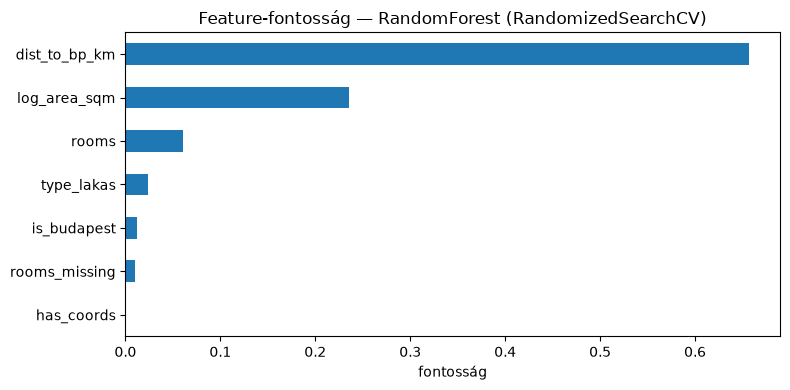

dist_to_bp_km    0.656624
log_area_sqm     0.235746
rooms            0.061075
type_lakas       0.023579
is_budapest      0.012700
rooms_missing    0.010277
has_coords       0.000000
dtype: float64

In [9]:
importances = pd.Series(rf_final.feature_importances_, index=FEATURES_RESTRICTED).sort_values()

importances.plot(kind="barh", title=f"Feature-fontosság — {rf_final_label}")
plt.xlabel("fontosság")
plt.tight_layout()
plt.show()

importances.sort_values(ascending=False)


**Megfigyelés:** a `dist_to_bp_km` (Budapest-távolság) és a `log_area_sqm`
(alapterület) adja a predikció nagy részét, a szobaszám és a `is_budapest`
bináris jelző ehhez képest alig hordoz plusz infót — ez értelmes, mert a
`dist_to_bp_km` folytonos jellemzőként finomabban fejezi ki a helyszín
hatását, mint a bináris `is_budapest`.


## Predikció vs. valós érték, és reziduumok (végső Random Forest)

Az utolsó ábrán megnézzük, hol hibázik a legjobb modell: alul- vagy
felülbecsüli-e szisztematikusan egyes ár-tartományokat.


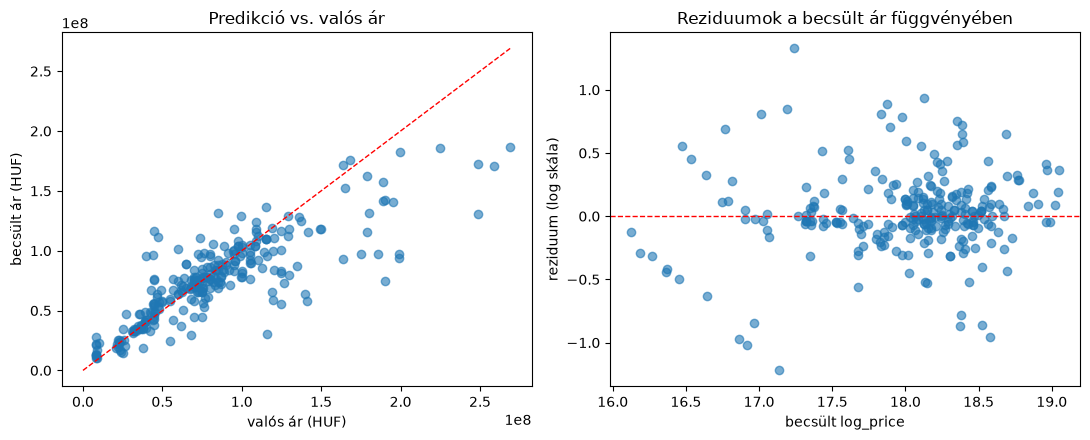

Legnagyobb abszolút hibájú teszt-sorok:


,valós_ár_HUF,becsült_ár_HUF,abs_hiba_HUF
522,249000000.0,1.304319e+08,1.185681e+08
534,190000000.0,7.431251e+07,1.156875e+08
1432,199000000.0,9.350287e+07,1.054971e+08
1019,199000000.0,9.687501e+07,1.021250e+08
1417,186000000.0,9.687501e+07,8.912499e+07
411,259000000.0,1.711400e+08,8.785998e+07
84,115990000.0,3.075782e+07,8.523218e+07
478,141000000.0,5.804508e+07,8.295492e+07
416,269000000.0,1.870452e+08,8.195485e+07
1410,174900000.0,9.750922e+07,7.739078e+07


In [10]:
X_train, X_test, y_train, y_test = split_clean
pred_test = rf_final.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(np.expm1(y_test), np.expm1(pred_test), alpha=0.6)
lims = [0, max(np.expm1(y_test).max(), np.expm1(pred_test).max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("valós ár (HUF)")
axes[0].set_ylabel("becsült ár (HUF)")
axes[0].set_title("Predikció vs. valós ár")

residuals = y_test - pred_test
axes[1].scatter(pred_test, residuals, alpha=0.6)
axes[1].axhline(0, color="r", linestyle="--", linewidth=1)
axes[1].set_xlabel("becsült log_price")
axes[1].set_ylabel("reziduum (log skála)")
axes[1].set_title("Reziduumok a becsült ár függvényében")

plt.tight_layout()
plt.show()

print("Legnagyobb abszolút hibájú teszt-sorok:")
worst = pd.DataFrame({
    "valós_ár_HUF": np.expm1(y_test),
    "becsült_ár_HUF": np.expm1(pred_test),
    "abs_hiba_HUF": np.abs(np.expm1(y_test) - np.expm1(pred_test)),
}).sort_values("abs_hiba_HUF", ascending=False).head(10)
worst


## Összefoglalás és következő lépés

- A **Random Forest** konzisztensen jobban teljesít, mint a lineáris/Ridge
  regresszió — az ár–jellemző kapcsolat nem lineáris.
- A `RandomizedSearchCV`-vel hangolt Random Forest (3. kísérlet adatain)
  teszt **R² ≈ 0,78**, **MAPE ≈ 22%** — ez a bővült (~1300+ soros) ház+lakás,
  kiugró érték nélküli adatkészleten érdemben jobb, mint a fix
  hiperparaméterekkel elért R² ≈ 0,74 / MAPE ≈ 26%.
- Egy tanulság az adatbővítésből: egyetlen hibás (irreálisan alacsony árú)
  sor a 2. kísérlet teszthalmazába kerülve a MAPE-et és az R²-t is
  drasztikusan megronthatja — ez megerősíti, hogy az összesített metrikák
  mellett mindig érdemes megnézni a legnagyobb hibájú egyedi eseteket is
  (ld. a reziduum-elemzés "legnagyobb abszolút hibájú" táblázatát).
- A legnagyobb hibaforrás vélhetően a **településszintű** árkülönbségek
  (a `dist_to_bp_km` csak Budapest-közelséget fejez ki, a többi település
  közötti eltérést nem), valamint az **állapot** (`condition` oszlop, amit
  jelenleg egyáltalán nem használ a modell) és egyéb, jelenleg nem
  gyűjtött jellemzők (pl. emelet, energetikai besorolás) hiánya.
- Következő lépésként érdemes: (1) `condition` beépítése jellemzőként,
  (2) további adatminőségi hibák (irreális ár/m²) szisztematikus
  kiszűrése, nem csak percentilis-alapú jelölése, (3) településszintű
  csoportosított átlag-ár mint jellemző (target encoding), (4) a reziduum-
  alapú anomália-detektálás (plan.md D) pont), amint a modell stabilabb.
